Here is where I will make my pretty plots

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc
import astropy.units as u
import astropy.coordinates as coord
import astropy as ap

df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')


df1["Age0"]=df1["Age"].str.split(" ±").str[0].astype(float)
df1["Age_error"]=df1["Age"].str.split(" ±").str[1].astype(float)
df1["Name"] = "NGC " + df1["NGC"].astype(float).astype("Int64").astype(str)
harris_p2["ID"] = harris_p2["ID"].astype(str).str.strip().str.upper()
df1["Name"] = df1["Name"].astype(str).str.strip().str.upper()

rc('text', usetex=False)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
Ra = pd.to_numeric(harris_p1['RA'],errors='coerce')
Dec = pd.to_numeric(harris_p1['DEC'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR= pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
mask = mtlc > -0.8
log_tc= pd.to_numeric(harris_p3['lg_tc'],errors='coerce')
log_th= pd.to_numeric(harris_p3['lg_th'],errors='coerce')
## Copied of Tobias
VmR = pd.to_numeric(harris_p2['V-R'],errors='coerce')
UmB = pd.to_numeric(harris_p2['U-B'],errors='coerce')
VmI = pd.to_numeric(harris_p2['V-I'],errors='coerce')
V_hb = pd.to_numeric(harris_p2['V_HB'],errors='coerce')
## Correct colour values for foreground reddening
E_BmV = pd.to_numeric(harris_p2['E(B-V)'],errors='coerce')
BmV0=BmV - E_BmV
VmR0=VmR - 0.72*E_BmV
VmI0=VmI - 1.24*E_BmV
UmB0=UmB - 0.72*E_BmV
#Coefficients calculated from Cardelli et al. 1989, ApJ, 345, 245
Age = pd.to_numeric(df1['Age0'],errors='coerce')
Age_e = pd.to_numeric(df1['Age_error'],errors='coerce') 
#Convert RA and DEC to degrees

Ra_rad = coord.Angle(Ra, unit=u.hourangle).rad
Dec_rad = coord.Angle(Dec, unit=u.degree).rad
## Merge age and harris dataframes
merged_df = harris_p2.merge(
    df1[["Name", "Age0"]],
    left_on="ID",
    right_on="Name",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "R_gc"]],
    on="ID",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "X", "Y", "Z", "RA", "DEC", "R_Sun" ]],
    on="ID",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p2[["ID", "M_V,t"]],
    on="ID",
    how="left",
    validate="many_to_one"
)
merged_df['RA'] = coord.Angle(merged_df['RA'], unit=u.hourangle).rad
merged_df['DEC'] = coord.Angle(merged_df['DEC'], unit=u.degree).rad
print(merged_df)


            ID [Fe/H]  wt  E(B-V)   V_HB  (m-M)V    V_t M_V,t_x   U-B   B-V  \
0      NGC 104  -0.72  10    0.04  14.06   13.37   3.95   -9.42  0.37  0.88   
1      NGC 288  -1.32   3    0.03  15.44   14.84   8.09   -6.75  0.08  0.65   
2      NGC 362  -1.26   5    0.05  15.44   14.83    6.4   -8.43  0.16  0.77   
3    WHITING 1   -0.7   1    0.03  18.18   17.49  15.03   -2.46               
4     NGC 1261  -1.27   3    0.01  16.70   16.09   8.29    -7.8  0.13  0.72   
..         ...    ...  ..     ...    ...     ...    ...     ...   ...   ...   
152   NGC 7089  -1.65   5    0.06  16.05   15.50   6.47   -9.03  0.09  0.66   
153   NGC 7099  -2.27   4    0.03  15.10   14.64   7.19   -7.45  0.03   0.6   
154     PAL 12  -0.85   6    0.02  17.13   16.46  11.99   -4.47  0.34  1.07   
155     PAL 13  -1.88   2    0.05  17.75   17.23  13.47   -3.76  0.11  0.76   
156   NGC 7492  -1.78   5    0.00  17.63   17.10  11.29   -5.81  0.23  0.42   

     ...      Name   Age0  R_gc    X     Y     Z   

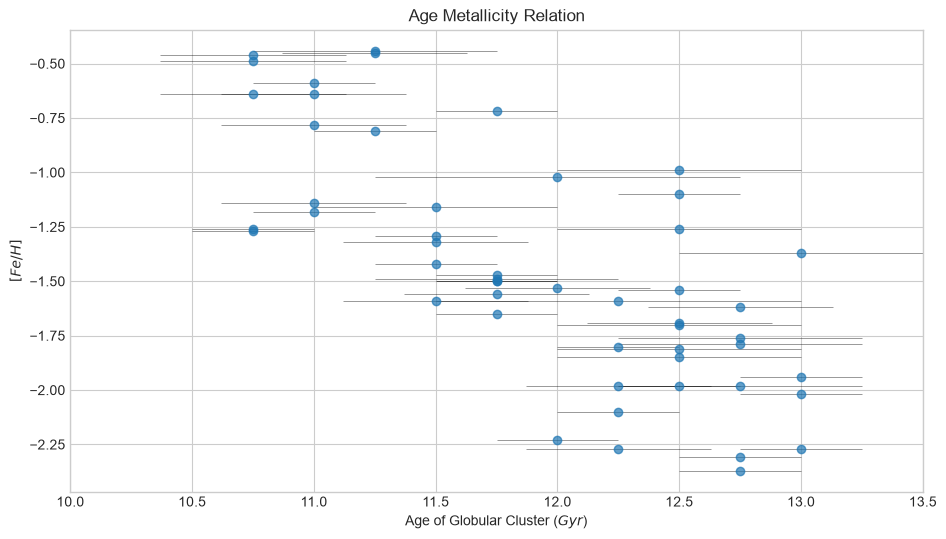

In [56]:
#Plot Age vs Mtlc
Age_df = merged_df.dropna(subset=['Age0', '[Fe/H]', '[Fe/H]'])
Age_df['[Fe/H]']= pd.to_numeric(Age_df['[Fe/H]'],errors='coerce')

plt.figure(figsize=(11,6))
plt.errorbar(Age_df['Age0'], Age_df['[Fe/H]'], xerr=Age_e, marker='o', linestyle='', ecolor='black',elinewidth=0.4, alpha=0.7)
plt.xlabel('Age of Globular Cluster ($Gyr$)')
plt.ylabel('$[Fe/H]$')
plt.title('Age Metallicity Relation')
plt.xlim(left=10, right=13.5)

plt.show()

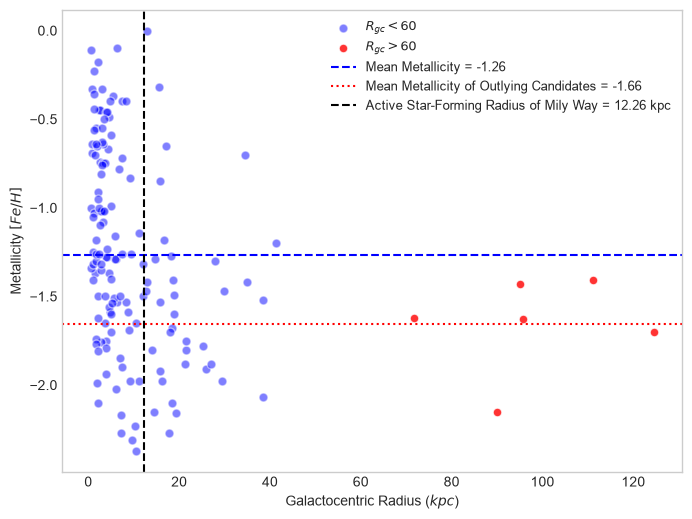

In [57]:
#Ben Fig 1 - Identifying the initial Candidates
#Mask top 6 clusters in R
mask_low = R_gc < 60
mask_high = R_gc >= 60

#Active Star-Forming Radius
r_active = 40000*u.lyr.to(u.kpc)

#Find Mean mtlc of Outliers
R_Mask_60 = R_gc >= 60

df_filtered0 = harris_p1[R_Mask_60]
df_filtered1=harris_p2[R_Mask_60]

p2 = harris_p2[["ID", "[Fe/H]"]].copy()

# Standardise IDs in both dataframes
df_filtered0["ID"] = (
    df_filtered0["ID"].astype(str).str.strip().str.upper()
)
p2["ID"] = p2["ID"].astype(str).str.strip().str.upper()

df_filtered = df_filtered0.merge(
    p2,
    on="ID",
    how="left",
    validate="many_to_one"
)
mean_mtlc_acc = pd.to_numeric(df_filtered['[Fe/H]'], errors = "coerce").mean()

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(8,6))
plt.scatter(R_gc[mask_low], mtlc[mask_low],
            color="blue", label="$R_{gc} < 60$", alpha=0.5, s=40, edgecolors="white")

plt.scatter(R_gc[mask_high], mtlc[mask_high],
            color="red", label="$R_{gc} > 60$", alpha=0.8, s=40, edgecolors="white")

# Add line for avg mtlc
plt.axhline(mtlc.mean(), color="blue", linestyle="--",
            label=f"Mean Metallicity = {mtlc.mean():.2f}")

plt.xlabel("Galactocentric Radius ($kpc$)")
plt.ylabel("Metallicity $[Fe/H]$")
# Add horizontal line
plt.axhline(
    mean_mtlc_acc,
    color="red",
    linestyle=":",
    label=f"Mean Metallicity of Outlying Candidates = {mean_mtlc_acc:.2f}"
)
plt.axvline(
    r_active,
    c="black",
    linestyle="--",
    label=f"Active Star-Forming Radius of Mily Way = {r_active:.2f} kpc"

)
plt.grid(False)
plt.legend(fontsize=9)
plt.show()

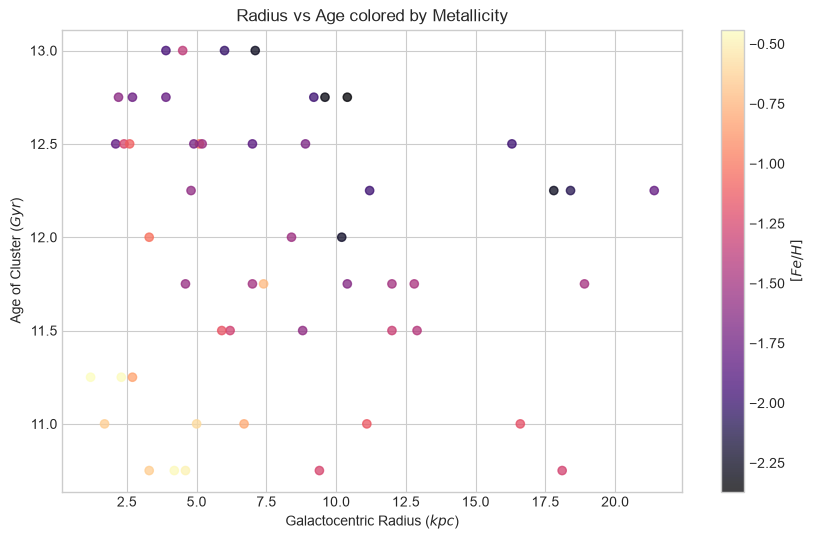

In [58]:
#Define a dataframe for Age (logistically helpful)
Age_df = merged_df.dropna(subset=['Age0', '[Fe/H]', '[Fe/H]'])
Age_df['[Fe/H]']= pd.to_numeric(Age_df['[Fe/H]'],errors='coerce')
Age_df['R_gc']= pd.to_numeric(Age_df['R_gc'],errors='coerce')



#Plot Age vs R_gc with mtlc colour
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(10,6), )
plt.scatter(Age_df['R_gc'], Age_df['Age0'], c=Age_df['[Fe/H]'], cmap='magma', vmin=Age_df['[Fe/H]'].min(), vmax=Age_df['[Fe/H]'].max(), alpha=0.75)
plt.xlabel('Galactocentric Radius ($kpc$)')
plt.ylabel('Age of Cluster ($Gyr$)')
plt.title('Radius vs Age colored by Metallicity')
plt.colorbar(label='$[Fe/H]$')
plt.legend
plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

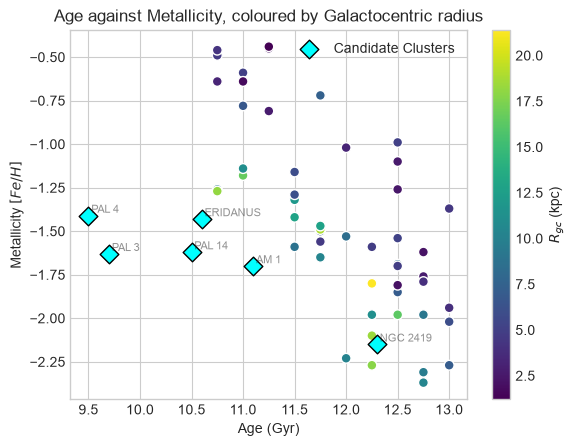

In [59]:


#Plot Age-Radius_Metallicity in new form with Candidate Clusters
filtered_age_list = np.array([11.1, 10.6, 12.3, 9.7, 9.5, 10.5])
#Ages obtained from Kruijsen et al 2019 (https://academic.oup.com/mnras/article/486/3/3180/5040776#134288585)
#Unertainties ignored
#Filtered Data Frame includes 6 outliers
df_filtered["Age"] = filtered_age_list
df_filtered["[Fe/H]"]=pd.to_numeric(df_filtered["[Fe/H]"])

plt.figure()
sc = plt.scatter(Age_df['Age0'], Age_df['[Fe/H]'], c=Age_df["R_gc"], cmap='viridis', edgecolors="white", s=50)
plt.scatter(
    df_filtered['Age'],
    pd.to_numeric(df_filtered['[Fe/H]'], errors='coerce'),
    color='cyan',
    edgecolors='black',
    linewidths=1,
    s=90,
    marker='D',
    label='Candidate Clusters',
    zorder=3
)
for _, row in df_filtered.iterrows():
    plt.annotate(
        row["ID"],
        (row["Age"], row["[Fe/H]"]),
        fontsize=8,
        alpha=0.5,
        xytext=(2, 2),
        textcoords="offset points"
    )

plt.colorbar(sc, label='$R_{gc}$ (kpc)')
plt.xlabel('Age (Gyr)')
plt.ylabel('Metallicity $[Fe/H]$')
plt.title('Age against Metallicity, coloured by Galactocentric radius')
plt.legend()
plt.grid(True)
plt.show()


In [71]:

##DO NOT RUN THIS MORE THAN ONCE WILL RUIN PLOTS. If already done just run the whole page again. :(
harris_p1['RA'] = coord.Angle(harris_p1['RA'], unit=u.hourangle).rad
harris_p1['DEC'] = coord.Angle(harris_p1['DEC'], unit=u.degree).rad
candidate_list= np.array(["Eridanus", "NGC 2419", "Pal 3", "Pal 4", "Ko 1", "Pal 14", "NGC 7492", "NGC 4590", "NGC 5024", "NGC 5053", "NGC 5466", "NGC 6101", "NGC 6241", "NGC 6397", "NGC 6779", "NGC 7078", "NGC 7099", "NGC 362", "NGC 1261", "NGC 2419", "NGC 1851", "NGC 2808"])
candidate_df = harris_p1[harris_p1["ID"].isin(candidate_list)].copy()
candidate_index = candidate_df.index.tolist()
candidate_list


array(['Eridanus', 'NGC 2419', 'Pal 3', 'Pal 4', 'Ko 1', 'Pal 14',
       'NGC 7492', 'NGC 4590', 'NGC 5024', 'NGC 5053', 'NGC 5466',
       'NGC 6101', 'NGC 6241', 'NGC 6397', 'NGC 6779', 'NGC 7078',
       'NGC 7099', 'NGC 362', 'NGC 1261', 'NGC 2419', 'NGC 1851',
       'NGC 2808'], dtype='<U8')

In [68]:
##Find Statistics
mask1 = (Age_df["[Fe/H]"]<-1.97)
mask2 = (Age_df["[Fe/H]"]<-1) & (Age_df["Age0"]<11.2)
mask3 = (Age_df["[Fe/H]"]>-1.02)
len1 = len(Age_df[mask1]["ID"])
len2 = len(Age_df[mask2]["ID"])
len3 = len(Age_df[mask3]["ID"])

n_acc=len1+len2
n_situ=len3
n_total=len(Age_df["ID"])
p_acc=n_acc/n_total
p_situ=n_situ/n_total

#Print 'probability' of accreted or in situ
print(p_acc, p_situ)

len(candidate_list)

0.2692307692307692 0.21153846153846154


22

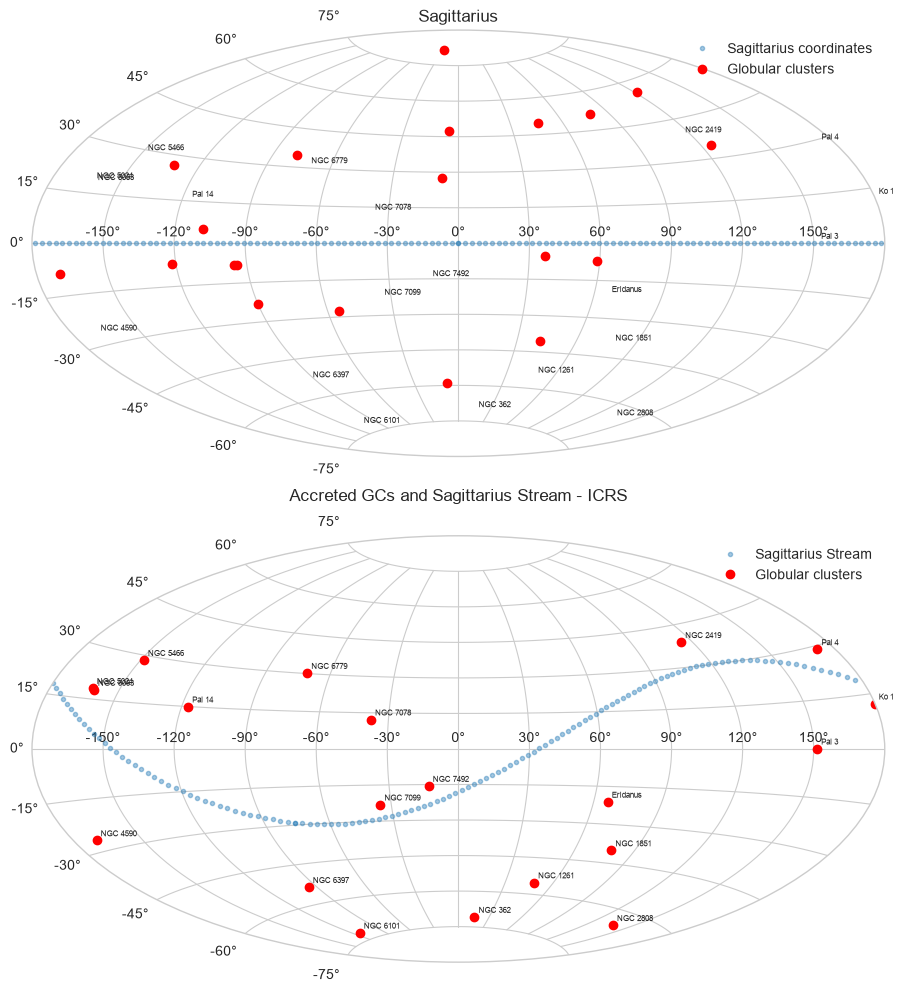

In [65]:
#Plot candidates on Saggitarius Stream:
##Code sourced from Astropy document "Create a new coordinate class (for the Sagittarius stream)"
import astropy.coordinates as coord
import astropy as ap
from astropy.coordinates import SkyCoord
from matplotlib import rc
import astropy.units as u
from astropy.coordinates import frame_transform_graph, rotation_matrix
class Sagittarius(coord.BaseCoordinateFrame):
    """A Heliocentric spherical coordinate system defined by the orbit
    of the Sagittarius dwarf galaxy, as described in
        https://ui.adsabs.harvard.edu/abs/2003ApJ...599.1082M
    and further explained in
        https://www.stsci.edu/~dlaw/Sgr/.

    Parameters
    ----------
    representation : `~astropy.coordinates.BaseRepresentation` or None
        A representation object or None to have no data (or use the other keywords)
    Lambda : `~astropy.coordinates.Angle`, optional, must be keyword
        The longitude-like angle corresponding to Sagittarius' orbit.
    Beta : `~astropy.coordinates.Angle`, optional, must be keyword
        The latitude-like angle corresponding to Sagittarius' orbit.
    distance : `~astropy.units.Quantity`, optional, must be keyword
        The Distance for this object along the line-of-sight.
    pm_Lambda_cosBeta : `~astropy.units.Quantity`, optional, must be keyword
        The proper motion along the stream in ``Lambda`` (including the
        ``cos(Beta)`` factor) for this object (``pm_Beta`` must also be given).
    pm_Beta : `~astropy.units.Quantity`, optional, must be keyword
        The proper motion in Declination for this object (``pm_ra_cosdec`` must
        also be given).
    radial_velocity : `~astropy.units.Quantity`, optional, keyword-only
        The radial velocity of this object.
    """
    default_representation = coord.SphericalRepresentation
    default_differential = coord.SphericalCosLatDifferential
    frame_specific_representation_info = {
        coord.SphericalRepresentation: [
            coord.RepresentationMapping("lon", "Lambda"),
            coord.RepresentationMapping("lat", "Beta"),
            coord.RepresentationMapping("distance", "distance"),
        ]
    }
SGR_PHI = (180 + 3.75) * u.degree  # Euler angles (from Law & Majewski 2010)
SGR_THETA = (90 - 13.46) * u.degree
SGR_PSI = (180 + 14.111534) * u.degree
SGR_MATRIX = (
    np.diag([1.0, 1.0, -1.0])
    @ rotation_matrix(SGR_PSI, "z")
    @ rotation_matrix(SGR_THETA, "x")
    @ rotation_matrix(SGR_PHI, "z")
)
@frame_transform_graph.transform(
    coord.StaticMatrixTransform, coord.Galactic, Sagittarius
)
def galactic_to_sgr():
    """Compute the Galactic spherical to heliocentric Sgr transformation matrix."""
    return SGR_MATRIX
@frame_transform_graph.transform(
    coord.StaticMatrixTransform, Sagittarius, coord.Galactic
)
def sgr_to_galactic():
    """Compute the heliocentric Sgr to spherical Galactic transformation matrix."""
    return SGR_MATRIX.swapaxes(-2, -1)


    
##Code sourced from Astropy document "Create a new coordinate class (for the Sagittarius stream)"

icrs = coord.SkyCoord(280.161732 * u.degree, 11.91934 * u.degree, frame="icrs")
sgr = icrs.transform_to(Sagittarius)
sgr = coord.SkyCoord(
    Lambda=np.linspace(0, 2 * np.pi, 128) * u.radian,
    Beta=np.zeros(128) * u.radian,
    frame="sagittarius",
)
icrs = sgr.transform_to(coord.ICRS)

#Create Candidate List
candidate_list= np.array(["Eridanus", "NGC 2419", "Pal 3", "Pal 4", "Ko 1", "Pal 14", "NGC 7492", "NGC 4590", "NGC 5024", "NGC 5053", "NGC 5466", "NGC 6101", "NGC 6241", "NGC 6397", "NGC 6779", "NGC 7078", "NGC 7099", "NGC 362", "NGC 1261", "NGC 2419", "NGC 1851", "NGC 2808"])
candidate_df = harris_p1[harris_p1["ID"].isin(candidate_list)].copy()
candidate_index = candidate_df.index.tolist()

#Turn coords into GC
icrs_gc = SkyCoord(
    ra=candidate_df["RA"].to_numpy() * u.rad,
    dec=candidate_df["DEC"].to_numpy() * u.rad,
    frame="icrs"
)

# Transform to Saggitarius
sgr_gc = icrs_gc.transform_to(sgr.frame)
#Plot it all
fig, axes = plt.subplots(
    2, 1, figsize=(10, 10),
    subplot_kw={"projection": "aitoff"}
)

# Sagittarius coords
axes[0].plot(
    sgr.Lambda.wrap_at(180 * u.deg).radian,
    sgr.Beta.radian,
    linestyle="none", marker=".", alpha=0.4,
    label="Sagittarius coordinates"
)

#My GCs
axes[0].plot(
    sgr_gc.Lambda.wrap_at(180 * u.deg).radian,
    sgr_gc.Beta.radian,
    linestyle="none", marker="o", color="red",
    markersize=6, label="Globular clusters"
)

axes[0].set_title("Sagittarius")
axes[0].grid(True)
axes[0].legend()

#ICRS coords
axes[1].plot(
    icrs.ra.wrap_at(180 * u.deg).radian,
    icrs.dec.radian,
    linestyle="none", marker=".", alpha=0.4,
    label="Sagittarius Stream"
)
#My GCs
axes[1].plot(
    icrs_gc.ra.wrap_at(180 * u.deg).radian,
    icrs_gc.dec.radian,
    linestyle="none", marker="o", color="red",
    markersize=6, label="Globular clusters"
)

axes[1].set_title("Accreted GCs and Saggitarius Stream - ICRS")
axes[1].grid(True)
axes[1].legend()

for i, name in enumerate(candidate_df["ID"]):

    axes[0].annotate(
            name,
            (
                icrs_gc.ra.wrap_at(180 * u.deg).radian[i],
                icrs_gc.dec.radian[i]
            ),
            fontsize=6,
            xytext=(3, 3),
            textcoords="offset points"
        )
    
    axes[1].annotate(
        name,
        (
            icrs_gc.ra.wrap_at(180 * u.deg).radian[i],
            icrs_gc.dec.radian[i]
        ),
        fontsize=6,
        xytext=(3, 3),
        textcoords="offset points"
    )
axes[1].set_title(
    "Accreted GCs and Sagittarius Stream - ICRS",
    pad=25
)
plt.tight_layout()
plt.show()

#Only the second plot looks nice.